# Où naît le flou ? — exécution sur Kaggle (GPU T4)

**Une session = un « Save & Run All (Commit) »** : il tourne en arrière-plan (fenêtre fermée, machine en veille), 12 h au plus.

L'état du projet (`runs/`, `reports/`) vit dans le Dataset privé **`flou-wm-etat`**. La cellule 1 le recopie dans
`/kaggle/working/flou_wm`, l'entraînement reprend au dernier checkpoint, puis `save_state()` publie une **nouvelle version**
du Dataset. Les données (`data/`) se régénèrent à l'identique à chaque session.

**Déroulé de la campagne** (variable `STAGE` de la cellule 0)
1. `STAGE = 'first_run'` : finir et évaluer **seulement** `core-regression-p0.30-s0`, puis vérifier qu'il n'y a pas de
   surapprentissage (courbes, H0b). C'est le contrôle demandé après l'incident J6 (données portées à 400 000 transitions).
2. Si le contrôle est bon : `STAGE = 'core_control'`, les 12 runs prioritaires (cœur + contrôles), en 2 ou 3 sessions.
3. Une fois, à la **prochaine** session, en plus du reste : `RUN_REEVAL = True` et `RUN_SIGMA_SWEEP = True`,
   pour que tous les runs portent les mesures décidées le 17 novembre (J9). Environ 17 min, avant l'entraînement.
   Les remettre à `False` ensuite.
4. Quand les 12 runs sont évalués : `RUN_ANALYSIS = True` (étape 8), puis l'extension « décision » si on la fait.

**Avant chaque session** : panneau de droite, accélérateur **GPU T4 x2**, **Internet On**, entrée **`flou-wm-etat`** sur sa
**dernière** version (accepter la mise à jour proposée), secret **`flou-wm`** coché (Add-ons → Secrets). Puis
**Save Version → Save & Run All (Commit)**.

Filet de sécurité : `/kaggle/working/flou_wm` devient aussi la sortie (*Output*) de la version ; si l'envoi au Dataset
échoue, les fichiers restent récupérables là.

La cellule du notebook Colab qui archivait le run à 100 000 transitions et vidait `runs/` n'existe pas ici : elle a déjà
servi (archive sur Drive) et la relancer effacerait le run en cours.

## 0. Réglages de la session

In [1]:
# ===== Session settings: the only cell to edit between sessions =====
STAGE = 'core_control'     # 'first_run'    : finish + evaluate FIRST_RUN only, then check for overfitting (J6)
                           # 'core_control' : the 12 priority runs (core + controls), once 'first_run' is validated
                           # 'none'         : no training (analysis or decision extension only)
FIRST_RUN = 'core-regression-p0.30-s0'
STEPS = 34800              # steps per run (plan, step 6, 38 h budget): do NOT change during the campaign
MAX_HOURS = 10             # Kaggle session: 12 h max -> keep ~2 h for evaluation and saving
RUN_TESTS = False          # steps 2-3: already passed on Kaggle (all [OK]); set True again if the code changes
RUN_ANALYSIS = False       # step 8: once the 12 core + control runs are evaluated
RUN_REEVAL = False         # re-evaluate every finished run (--force): needed once, so that all runs
                           # carry the rail-restricted measure added on 17 Nov (DECISIONS.md)
RUN_SIGMA_SWEEP = False    # one Euler step from several starting sigmas, diffusion runs only (J9)
RUN_DECISION_L1 = False    # step 9, level 1 + H0e/H0f controls: fast, after the analysis
RUN_DECISION_L2 = False    # step 9, level 2: LONG (read the corresponding cell before enabling it)

DATASET = 'cedricdada/flou-wm-etat'
SECRET_NAME = 'flou-wm'
MAX_SECONDS = int(MAX_HOURS * 3600)

## 1. GPU, état sauvegardé et dépôt

In [2]:
!nvidia-smi -L
import os, glob, json, shutil, subprocess, time, zipfile
BASE_DIR = '/kaggle/working/flou_wm'
os.makedirs(BASE_DIR, exist_ok=True)


def restore_state(root):
    # Trouve le dossier qui contient runs/ sous `root` et le copie dans BASE_DIR.
    for current, dirs, files in os.walk(root):
        if 'runs' in dirs:
            shutil.copytree(current, BASE_DIR, dirs_exist_ok=True)
            return current
    return None


archives = glob.glob('/kaggle/input/**/etat.zip', recursive=True)
if archives:                                    # zip resté tel quel
    zipfile.ZipFile(archives[0]).extractall('/tmp/etat')
    state_source = restore_state('/tmp/etat')
else:                                           # Kaggle a décompressé le zip
    state_source = restore_state('/kaggle/input')
print("état repris depuis :", state_source or "RIEN TROUVÉ : départ à zéro (entrée flou-wm-etat ajoutée ?)")


def save_state(note):
    # Publie runs/ et reports/ comme nouvelle version du Dataset. N'interrompt jamais le notebook.
    try:
        from kaggle_secrets import UserSecretsClient
        token = UserSecretsClient().get_secret(SECRET_NAME)
        os.environ['KAGGLE_USERNAME'] = DATASET.split('/')[0]
        os.environ['KAGGLE_KEY'] = token            # ancien format de clé
        os.environ['KAGGLE_API_TOKEN'] = token      # nouveau format (onglet « API Tokens »)
        upload_dir = '/tmp/up'
        shutil.rmtree(upload_dir, ignore_errors=True)
        os.makedirs(f'{upload_dir}/etat')
        for name in ('runs', 'reports'):
            if os.path.isdir(f'{BASE_DIR}/{name}'):
                shutil.copytree(f'{BASE_DIR}/{name}', f'{upload_dir}/etat/{name}')
        shutil.make_archive(f'{upload_dir}/etat', 'zip', f'{upload_dir}/etat')
        shutil.rmtree(f'{upload_dir}/etat')         # n'envoyer que etat.zip
        json.dump({"id": DATASET, "title": DATASET.split('/')[1], "licenses": [{"name": "other"}]},
                  open(f'{upload_dir}/dataset-metadata.json', 'w'))
        version_note = f"{note} ({time.strftime('%Y-%m-%d %H:%M')} UTC)"
        size_mb = os.path.getsize(f'{upload_dir}/etat.zip') / 1e6
        print(f"envoi de etat.zip ({size_mb:.0f} Mo) : {version_note}")
        result = subprocess.run(['kaggle', 'datasets', 'version', '-p', upload_dir, '-m', version_note],
                                capture_output=True, text=True)
        print(result.stdout[-1500:], result.stderr[-1500:])
        print("SAUVEGARDE OK" if result.returncode == 0 else
              f"ÉCHEC DE LA SAUVEGARDE (code {result.returncode}) : récupérer {BASE_DIR} dans l'Output de la version")
    except Exception as e:
        print(f"ÉCHEC DE LA SAUVEGARDE ({type(e).__name__}: {e}) : récupérer {BASE_DIR} dans l'Output de la version")


!ls {BASE_DIR}/runs/*/

# Garde-fou : en 'core_control', le premier run doit déjà être évalué dans l'état repris (sinon l'entrée est périmée)
if STAGE == 'core_control' and not os.path.exists(f'{BASE_DIR}/runs/{FIRST_RUN}/eval.json'):
    raise RuntimeError("Entrée flou-wm-etat périmée (le premier run n'y est pas évalué) : "
                       "mettre l'entrée sur sa dernière version avant de lancer la session.")

GPU 0: Tesla T4 (UUID: GPU-605753f2-086d-3239-f228-88ec09702c7a)
GPU 1: Tesla T4 (UUID: GPU-04ba15c0-8ffc-9f57-60ae-e3d5fc8f7165)
état repris depuis : /kaggle/input/datasets/cedricdada/flou-wm-etat
ckpt.pt       eval_arrays.npz  fig_training.png  log.jsonl	   spec.json
compute.json  eval.json        final.pt		 samples_main.png  train.json


In [3]:
# Cloner le dépôt (dépôt privé : mettre un jeton -> https://<TOKEN>@github.com/...). Exige Internet On.
REPO_URL = 'https://github.com/CedricDada/flou-world-models.git'
REPO_DIR = '/content/flou_wm'
# Clone neuf à chaque session : c'est la seule façon sûre d'avoir le dernier code.
if os.path.isdir(REPO_DIR):
    %cd /content
    shutil.rmtree(REPO_DIR)
!git clone -q $REPO_URL $REPO_DIR
%cd $REPO_DIR
!git log --oneline -1

# runs/ reports/ data/ du dépôt pointent vers BASE_DIR (qui part dans le Dataset et dans l'Output de la version)
for name in ('runs', 'reports', 'data'):
    os.makedirs(f'{BASE_DIR}/{name}', exist_ok=True)
    if os.path.isdir(name) and not os.path.islink(name):
        shutil.rmtree(name)
    if not os.path.islink(name):
        os.symlink(f'{BASE_DIR}/{name}', name)

# Kaggle fournit déjà numpy, scipy, matplotlib et pillow : n'installer que ce qui manque,
# pour ne pas risquer de remplacer la numpy sur laquelle le PyTorch préinstallé est compilé.
import importlib.util
missing = [package for module, package in (('numpy', 'numpy'), ('scipy', 'scipy'), ('matplotlib', 'matplotlib'),
                                           ('PIL', 'pillow'), ('pytest', 'pytest'))
           if importlib.util.find_spec(module) is None]
if missing:
    !pip install -q {' '.join(missing)}
print('paquets installés :', ' '.join(missing) if missing else 'aucun, tout était présent')

/content/flou_wm
be1f64f (HEAD -> main, origin/main, origin/HEAD) Surapprentissage corrige (400 000 transitions), relecture externe appliquee, journal de bord
paquets installés : aucun, tout était présent


## 2-3. Tests NumPy et test de fumée PyTorch (une fois, ou quand le code change)

In [4]:
if RUN_TESTS:
    !python -m pytest -q -x
    !python scripts/smoke_test.py
else:
    print("tests sautés (RUN_TESTS = False)")

tests sautés (RUN_TESTS = False)


## 4. Données

Régénérées à chaque session (une minute environ), identiques d'une session à l'autre.

In [5]:
!python scripts/generate_data.py --split train --p 0.0 0.1 0.3 0.5 --n-transitions 400000
!python scripts/generate_data.py --split val   --p 0.0 0.1 0.3 0.5 --n-transitions 20000
!python scripts/generate_data.py --split test  --p 0.0 0.1 0.3 0.5 --n-bifurcations 2000   # H2b exige >= 1 000 images NETTES par graine

p=0.00  data/p0.00/train_random.npz  (1.3 Mo, 2.0 s)
p=0.00  data/p0.00/train_greedy.npz  (1.3 Mo, 2.0 s)
p=0.10  data/p0.10/train_random.npz  (1.3 Mo, 2.0 s)
p=0.10  data/p0.10/train_greedy.npz  (1.4 Mo, 2.0 s)
p=0.30  data/p0.30/train_random.npz  (1.3 Mo, 1.9 s)
p=0.30  data/p0.30/train_greedy.npz  (1.4 Mo, 1.9 s)
p=0.50  data/p0.50/train_random.npz  (1.3 Mo, 1.9 s)
p=0.50  data/p0.50/train_greedy.npz  (1.4 Mo, 1.9 s)
p=0.00  data/p0.00/val_random.npz  (0.1 Mo, 0.2 s)
p=0.00  data/p0.00/val_greedy.npz  (0.1 Mo, 0.2 s)
p=0.10  data/p0.10/val_random.npz  (0.1 Mo, 0.2 s)
p=0.10  data/p0.10/val_greedy.npz  (0.1 Mo, 0.2 s)
p=0.30  data/p0.30/val_random.npz  (0.1 Mo, 0.2 s)
p=0.30  data/p0.30/val_greedy.npz  (0.1 Mo, 0.2 s)
p=0.50  data/p0.50/val_random.npz  (0.1 Mo, 0.2 s)
p=0.50  data/p0.50/val_greedy.npz  (0.1 Mo, 0.2 s)
p=0.00  data/p0.00/test_bifurcation.npz  (0.1 Mo, 0.2 s)
p=0.10  data/p0.10/test_bifurcation.npz  (0.1 Mo, 0.2 s)
p=0.30  data/p0.30/test_bifurcation.npz  (0.1 Mo, 0.2 

## 5. Instrument de mesure (avant tout modèle)

Règle ρmax et contrôle H0a sans entraînement. Si H0a échoue, **ne mesurer aucun modèle**.

In [6]:
!python scripts/validate_instrument.py

8000 paires (A, B) sur 4 jeux de test ; δ dans [6.71, 7.65]
ρmax = 0.1599  (bruit synthétique σ = 0.01, quantile 0.995)
H0a (contrôle de l'instrument, sans entraînement) :
{
 "rho_max": 0.15988816883972015,
 "alpha_mae_mix": 0.0010484329686256811,
 "pure_a_ok": 0.994875,
 "pure_b_ok": 0.994625,
 "rho_pure_q995": 0.159971278492099,
 "rho_mix_max": 0.1667269972912107,
 "pure_ok": 0.99475,
 "mix_not_other": 0.99625,
 "broken_flagged_other": 1.0,
 "rho_broken_min": 0.3520697813821917,
 "noise_sigma": 0.01,
 "pass_alpha": true,
 "pass_pure": true,
 "pass": true
}
sensibilité au seuil :
   x0.5 : ρmax = 0.0799  {"pure_ok": 0.0, "alpha_mae_mix": 0.0010484329686256811, "broken_flagged_other": 1.0, "pass": false}
     x1 : ρmax = 0.1599  {"pure_ok": 0.99475, "alpha_mae_mix": 0.0010484329686256811, "broken_flagged_other": 1.0, "pass": true}
     x2 : ρmax = 0.3198  {"pure_ok": 1.0, "alpha_mae_mix": 0.0010484329686256811, "broken_flagged_other": 1.0, "pass": true}
rapport : reports/instrument.jso

## 6bis. Mesures décidées le 17 novembre (J9) — AVANT l'entraînement

Les deux sont **exploratoires** : elles ne changent aucun verdict, et sont déclarées dans
`docs/DECISIONS.md` avant toute analyse.

- `RUN_REEVAL` réévalue **tous** les runs terminés pour qu'ils portent la mesure restreinte au rail de la
  bifurcation. À faire **une fois**, sur les runs évalués avant le 17 novembre : quelques minutes par run,
  aucun réentraînement. Sans cela, la mesure n'existerait que sur une partie de la campagne.
- `RUN_SIGMA_SWEEP` mesure un pas d'Euler depuis plusieurs σ de départ, sur les runs de diffusion. Il dit
  *pourquoi* la diffusion à n = 1 donne 100 % d'images « autre », sans changer H2a.

**Pourquoi avant l'entraînement et non après.** Les deux coûtent ensemble environ 17 minutes, mesurées sur les
cinq runs déjà évalués (diffusion 5,2 min, jetons 2,9 min, régression 0,3 min). L'entraînement, lui, s'arrête
proprement à `MAX_HOURS` et reprend à la session suivante : il est donc le seul des deux qu'on peut se permettre
de tronquer. Placées après, ces 17 minutes risqueraient de pousser la session au-delà des 12 h et de faire sauter
la sauvegarde vers le Dataset.

`--force` ne sert qu'aux runs évalués **avant** le 17 novembre : depuis, `evaluate.py` écrit la clé `rail` de
lui-même, donc les runs évalués par cette session et les suivantes la portent sans rien demander.

In [ ]:
if RUN_REEVAL:
    !python scripts/evaluate.py --all --force
else:
    print("réévaluation sautée (RUN_REEVAL = False)")

if RUN_SIGMA_SWEEP:
    !python scripts/sigma_sweep.py --all
else:
    print("balayage de σ sauté (RUN_SIGMA_SWEEP = False)")

## 7. Entraînement

- `first_run` : `train.py` reprend `FIRST_RUN` au dernier checkpoint et le termine, puis `evaluate.py` l'évalue.
- `core_control` : `run_plan.py` enchaîne les 12 runs prioritaires (entraînement puis évaluation), reprend un run commencé
  au pas près et saute ceux qui sont finis.

Dans les deux cas, `--max-seconds` / `--max-hours` est un arrêt propre : le run en cours écrit son checkpoint et la session
suivante le reprend.

In [7]:
!python scripts/run_plan.py --steps {STEPS} --groups core control --dry    # état avant la session
if STAGE == 'first_run':
    !python scripts/train.py --run-id {FIRST_RUN} --steps {STEPS} --max-seconds {MAX_SECONDS}
    if os.path.exists(f'runs/{FIRST_RUN}/final.pt'):
        !python scripts/evaluate.py --run-id {FIRST_RUN}
    else:
        print(f"{FIRST_RUN} pas encore fini : relancer une session pour reprendre")
elif STAGE == 'core_control':
    !python scripts/run_plan.py --steps {STEPS} --max-hours {MAX_HOURS} --groups core control
else:
    print("pas d'entraînement (STAGE = 'none')")

[ 1/12] core-regression-p0.30-s0           évalué
[ 2/12] core-diffusion-p0.30-s0            à faire
[ 3/12] core-tokens-K256-p0.30-s0          à faire
[ 4/12] core-regression-p0.30-s1           à faire
[ 5/12] core-diffusion-p0.30-s1            à faire
[ 6/12] core-tokens-K256-p0.30-s1          à faire
[ 7/12] core-regression-p0.30-s2           à faire
[ 8/12] core-diffusion-p0.30-s2            à faire
[ 9/12] core-tokens-K256-p0.30-s2          à faire
[10/12] control-oracle-p0.30-s0            à faire
[11/12] control-regression-p0.00-s0        à faire
[12/12] control-diffusion-p0.00-s0         à faire
[ 1/12] core-regression-p0.30-s0           évalué
[ 2/12] core-diffusion-p0.30-s0            à faire
[ 3/12] core-tokens-K256-p0.30-s0          à faire
[ 4/12] core-regression-p0.30-s1           à faire
[ 5/12] core-diffusion-p0.30-s1            à faire
[ 6/12] core-tokens-K256-p0.30-s1          à faire
[ 7/12] core-regression-p0.30-s2           à faire
[ 8/12] core-diffusion-p0.30-s2  

## Contrôle du surapprentissage (incident J6)

Deux symptômes sont cherchés dans les journaux (`scripts/training_curves.py`) : la perte de validation qui **remonte**
depuis son minimum, et la perte d'entraînement qui passe **sous le plancher de Bayes** p(1−p)δ² (impossible sans
mémoriser l'issue des bifurcations). Puis, sur le run évalué : **H0b** (MSE entre 1,00 et 1,10 fois le plancher, pas de
fuite) et le flou de la régression (côté régression de H1). Référence du run raté J6 (100 000 transitions) : MSE/plancher
1,47, flou 22,5 %, autre 2,0 %, p̂ = 0,158, perte d'entraînement 0,46 fois le plancher, validation +49 % après le pas 14 000.

== core-diffusion-p0.30-s0
   main/val_loss : minimum 0.000356 au pas 34000, fin 0.000463 (+30.2%)  [ALERTE]
   figure : runs/core-diffusion-p0.30-s0/fig_training.png
== core-diffusion-p0.30-s1
   main/val_loss : minimum 0.000375 au pas 34000, fin 0.000388 (+3.4%)  [ok]
   figure : runs/core-diffusion-p0.30-s1/fig_training.png
== core-regression-p0.30-s0
   main/val_loss : minimum 0.000771 au pas 30000, fin 0.000775 (+0.5%)  [ok]
   figure : runs/core-regression-p0.30-s0/fig_training.png
== core-regression-p0.30-s1
   main/val_loss : minimum 0.000775 au pas 32000, fin 0.000783 (+1.0%)  [ok]
   figure : runs/core-regression-p0.30-s1/fig_training.png
== core-tokens-K256-p0.30-s0
   gpt/val_ce : minimum 0.494050 au pas 20880, fin 0.494050 (+0.0%)  [ok]
   vq/val_recon : minimum 0.000064 au pas 13920, fin 0.000064 (+0.0%)  [ok]
   figure : runs/core-tokens-K256-p0.30-s0/fig_training.png
== core-tokens-K256-p0.30-s1
   gpt/val_ce : minimum 0.580111 au pas 14000, fin 0.580111 (+0.0%)  [ok]
 

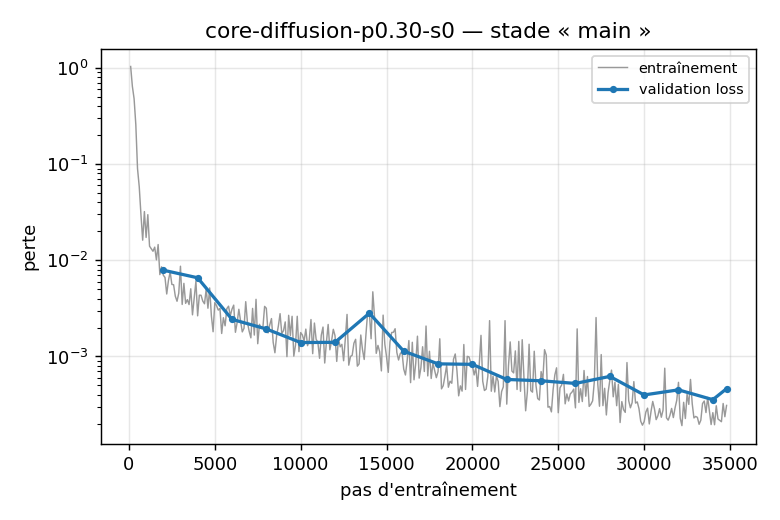

runs/core-diffusion-p0.30-s1/fig_training.png


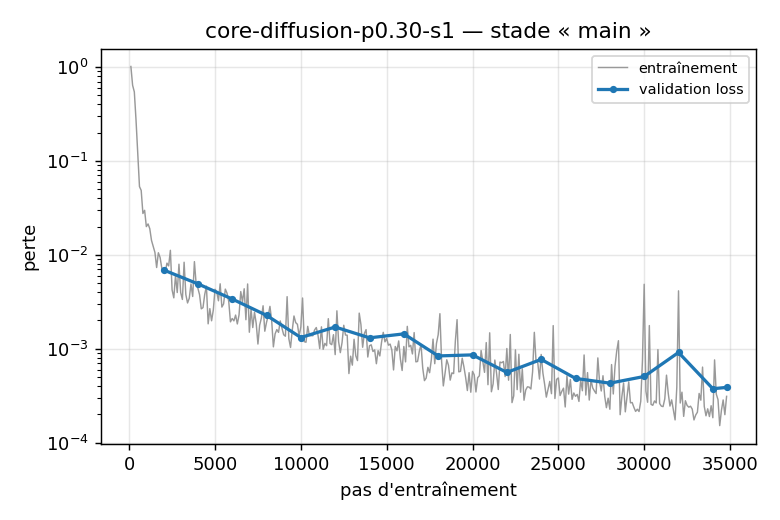

runs/core-regression-p0.30-s0/fig_training.png


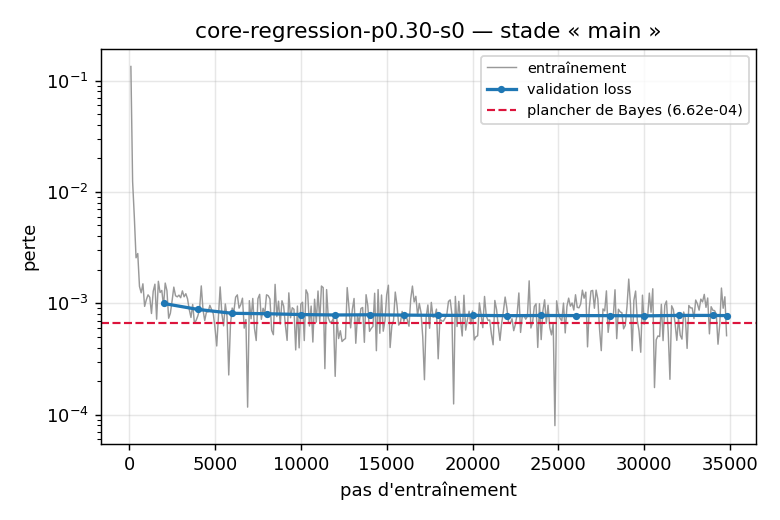

runs/core-regression-p0.30-s1/fig_training.png


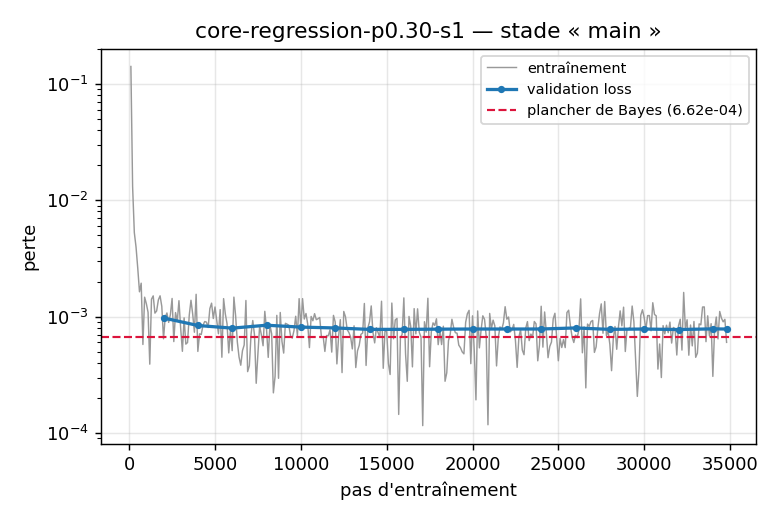

runs/core-tokens-K256-p0.30-s0/fig_training.png


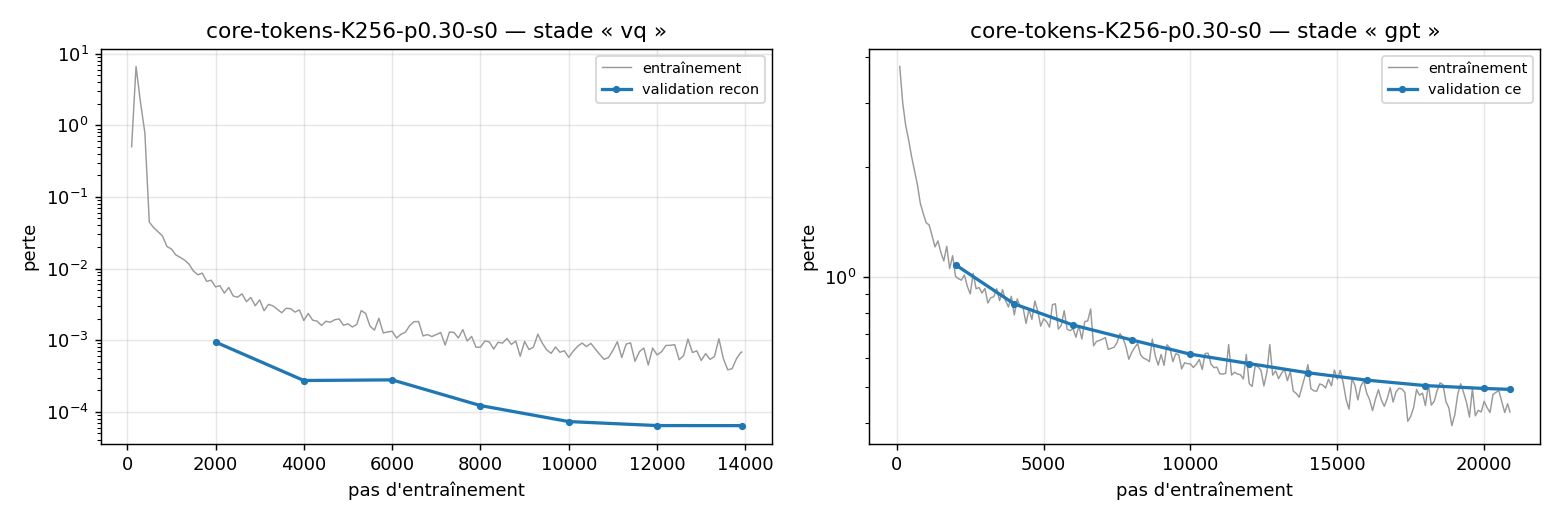

runs/core-tokens-K256-p0.30-s1/fig_training.png


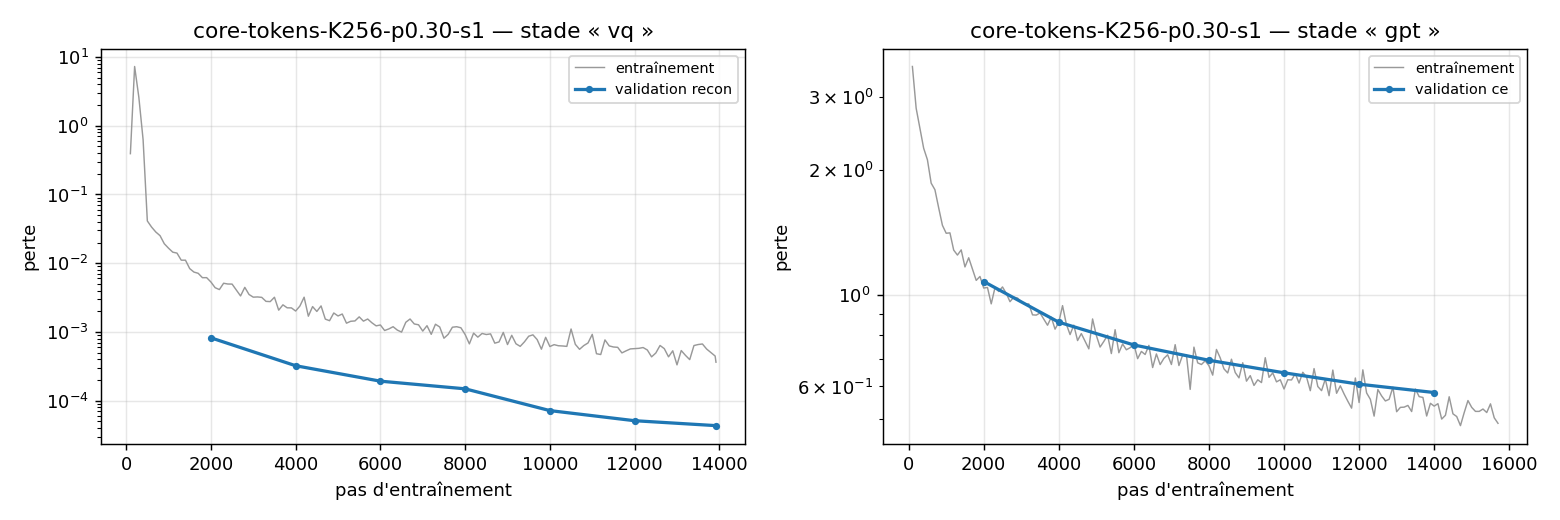

core-diffusion-p0.30-s0 n=1  (diffusion, ρmax = 0.1599, n = 2000 images)
  flou 0.0%   autre 100.0%   nettes 0.0%   p̂ = nan [nan ; nan]   rappel du petit objet 98.7%
core-diffusion-p0.30-s0 n=3  (diffusion, ρmax = 0.1599, n = 2000 images)
  flou 4.4%   autre 4.3%   nettes 91.2%   p̂ = 0.327 [0.306 ; 0.349]   rappel du petit objet 98.8%
core-diffusion-p0.30-s0 n=5  (diffusion, ρmax = 0.1599, n = 2000 images)
  flou 0.0%   autre 4.5%   nettes 95.5%   p̂ = 0.294 [0.273 ; 0.315]   rappel du petit objet 98.8%
core-diffusion-p0.30-s0 n=20  (diffusion, ρmax = 0.1599, n = 2000 images)
  flou 0.0%   autre 3.8%   nettes 96.2%   p̂ = 0.324 [0.303 ; 0.345]   rappel du petit objet 98.8%
core-diffusion-p0.30-s1 n=1  (diffusion, ρmax = 0.1599, n = 2000 images)
  flou 0.0%   autre 100.0%   nettes 0.0%   p̂ = nan [nan ; nan]   rappel du petit objet 98.4%
core-diffusion-p0.30-s1 n=3  (diffusion, ρmax = 0.1599, n = 2000 images)
  flou 5.4%   autre 5.5%   nettes 89.1%   p̂ = 0.255 [0.235 ; 0.276]   rappe

In [8]:
def report_run(run_id):
    # Résume eval.json : flou, autre, p̂, rappel du petit objet ; H0b pour la régression seulement.
    # Renvoie True ou False (H0b) pour un run de régression, None sinon.
    path = f'runs/{run_id}/eval.json'
    if not os.path.exists(path):
        print(f"{run_id} : pas encore évalué")
        return None
    evaluation = json.load(open(path))
    family = evaluation['spec']['family']
    h0b_passed = True
    for variant in evaluation['variants']:
        summary = variant['summary']
        n, counts, p_hat = summary['n'], summary['counts'], summary['p_hat']
        print(f"{run_id} {variant['variant']}  ({family}, ρmax = {summary['rho_max']:.4f}, n = {n} images)")
        if family == 'regression':      # H0b n'a de sens que pour la régression (l'oracle connaît la branche)
            h0b = variant['chk_h0b']
            print(f"  H0b : MSE / plancher de Bayes = {h0b['ratio_expected']:.3f} en espérance (attendu 1,00 à 1,10), "
                  f"{h0b['ratio_realized']:.3f} contre l'image tirée ; fuite z = {h0b['leak_z']:.1f} (alerte si > 3)"
                  f"  ->  {'RÉUSSI' if h0b['pass'] else 'ÉCHOUÉ'}")
            h0b_passed = h0b_passed and h0b['pass']
        print(f"  flou {counts['floue'] / n:.1%}   autre {counts['autre'] / n:.1%}"
              f"   nettes {(counts['nette-A'] + counts['nette-B']) / n:.1%}"
              f"   p̂ = {p_hat['value']:.3f} [{p_hat['ci_lo']:.3f} ; {p_hat['ci_hi']:.3f}]"
              f"   rappel du petit objet {summary['recall']['value']:.1%}")
        rail = summary.get('rail')      # mesure EXPLORATOIRE (DECISIONS.md, 17 nov.) : aucun verdict n'en depend
        if rail:
            cr = rail['counts']
            print(f"     au rail de la bifurcation (exploratoire) : flou {cr['floue'] / n:.1%}"
                  f"   autre {cr['autre'] / n:.1%}   nettes {(cr['nette-A'] + cr['nette-B']) / n:.1%}"
                  f"   p̂ = {rail['p_hat']['value']:.3f}")
    return h0b_passed if family == 'regression' else None


try:
    if STAGE == 'first_run':
        curve_args, runs_to_report = ['--run-id', FIRST_RUN], [FIRST_RUN]
    else:
        curve_args = ['--all']
        runs_to_report = sorted(os.path.basename(os.path.dirname(p)) for p in glob.glob('runs/*/eval.json'))
    curves = subprocess.run(['python', 'scripts/training_curves.py', *curve_args], capture_output=True, text=True)
    print(curves.stdout, curves.stderr)
    no_overfit_alert = curves.returncode == 0

    from IPython.display import Image, display
    for figure_path in sorted(glob.glob('runs/*/fig_training.png')):
        if STAGE != 'first_run' or FIRST_RUN in figure_path:
            print(figure_path)
            display(Image(figure_path))

    h0b_results = {run_id: report_run(run_id) for run_id in runs_to_report}
    if STAGE == 'first_run':
        h0b_ok = h0b_results.get(FIRST_RUN)
        print()
        if h0b_ok is None:
            print("=> run pas encore évalué : relancer la même session (STAGE = 'first_run').")
        elif h0b_ok and no_overfit_alert:
            print("=> FEU VERT : pas de surapprentissage détecté et H0b réussi. "
                  "Session suivante : STAGE = 'core_control'.")
        else:
            print("=> NE PAS lancer le cœur : "
                  + ("alerte de surapprentissage ; " if not no_overfit_alert else "")
                  + ("H0b échoué ; " if not h0b_ok else "")
                  + "comparer à J6 (docs/JOURNAL.md) et trancher avant la suite.")
except Exception as e:
    print(f"contrôle impossible ({type(e).__name__}: {e}) : la sauvegarde qui suit a quand même lieu")

## Sauvegarde de la session

Toujours exécutée, même si une cellule précédente a échoué à l'intérieur de son `try`.

In [9]:
save_state(f"STAGE = {STAGE}")
!python scripts/run_plan.py --steps {STEPS} --groups core control --dry    # état en fin de session

envoi de etat.zip (287 Mo) : STAGE = core_control (2026-11-17 06:17 UTC)
Starting upload for file etat.zip
Upload successful: etat.zip (273MB)
Dataset version is being created. Please check progress at https://www.kaggle.com/datasets/cedricdada/flou-wm-etat
 :04<00:03, 39.2MB/s]
 54%|█████▍    | 148M/273M [00:04<00:03, 39.6MB/s]
 56%|█████▌    | 153M/273M [00:04<00:03, 39.9MB/s]
 58%|█████▊    | 157M/273M [00:05<00:03, 40.3MB/s]
 59%|█████▉    | 162M/273M [00:05<00:02, 39.5MB/s]
 61%|██████    | 166M/273M [00:05<00:02, 39.5MB/s]
 63%|██████▎   | 171M/273M [00:05<00:02, 39.7MB/s]
 64%|██████▍   | 175M/273M [00:05<00:02, 40.1MB/s]
 66%|██████▌   | 180M/273M [00:05<00:02, 40.3MB/s]
 67%|██████▋   | 184M/273M [00:05<00:02, 39.3MB/s]
 69%|██████▉   | 189M/273M [00:05<00:02, 39.4MB/s]
 71%|███████   | 193M/273M [00:06<00:02, 39.6MB/s]
 72%|███████▏  | 198M/273M [00:06<00:01, 40.1MB/s]
 74%|███████▍  | 202M/273M [00:06<00:01, 40.3MB/s]
 76%|███████▌  | 207M/273M [00:06<00:01, 39.5MB/s]
 77%|█

## 8. Analyse (quand les 12 runs cœur + contrôles sont « évalué »)

Verdicts H0 à H3, tables, figures, rapport. Avant, la plupart des verdicts seraient « non évaluables » (H1 à H3 comparent
3 familles sur 3 graines). Puis, à la main : la relecture de 100 cas et le test A/B (voir `docs/EXPERIMENTS.md`).

In [10]:
if RUN_ANALYSIS:
    !python scripts/analyze.py
    try:
        from IPython.display import Markdown, Image, display
        display(Markdown(open('reports/report.md', encoding='utf-8').read()))
        for figure_path in sorted(glob.glob('reports/fig_*.png')):
            print(figure_path)
            display(Image(figure_path))
    except Exception as e:
        print("affichage du rapport impossible :", e)
else:
    print("analyse sautée (RUN_ANALYSIS = False)")

analyse sautée (RUN_ANALYSIS = False)


### Bandes d'images : ce que le modèle imagine

Illustrations seulement, aucun verdict n'en dépend.

In [11]:
if RUN_ANALYSIS:
    if os.path.exists('runs/core-regression-p0.30-s0/final.pt'):
        !python scripts/filmstrip.py --run-id core-regression-p0.30-s0 --gif
    if os.path.exists('runs/core-diffusion-p0.30-s0/final.pt'):
        !python scripts/filmstrip.py --run-id core-diffusion-p0.30-s0 --n-steps 3 --gif
    try:
        from IPython.display import Image, display
        for figure_path in sorted(glob.glob('runs/core-*/filmstrip_*.png')):
            print(figure_path)
            display(Image(figure_path))
    except Exception as e:
        print("affichage impossible :", e)

## 9. Extension « décision » (facultatif) : le flou change-t-il une décision ?

Hypothèses H4 et H5, guidées par PETS (arXiv:1805.12114), PlaNet (arXiv:1811.04551) et Objective Mismatch (arXiv:2002.04523) :
voir `docs/EXTENSION_DECISION.md`. Après l'analyse, sur les runs évalués.

In [12]:
if RUN_DECISION_L1:
    # H0f aux réglages du niveau 2 (DECISIONS.md, C7 révisé) : 32 suites, 20 parties ; puis le niveau 1, rapide
    !python scripts/validate_decision.py --games 20 --candidates 32
    !python scripts/evaluate_decision.py --all
else:
    print("extension niveau 1 sautée (RUN_DECISION_L1 = False)")

extension niveau 1 sautée (RUN_DECISION_L1 = False)


In [13]:
# Niveau 2 (planification dans le modèle) : LONG. Estimation du test de fumée sur T4 aux réglages par défaut :
# régression ~1 h, diffusion ~12 h, jetons ~66-75 h PAR RUN ; avec --games 20 --candidates 32, environ 5 fois moins
# (jetons ~15 h par run : plus qu'une session Kaggle). À décider avant de l'activer (DECISIONS.md, C7).
# Relancer après une coupure : les runs déjà faits sont sautés.
if RUN_DECISION_L2:
    !python scripts/evaluate_decision.py --all --level 2 --games 4 --game-steps 10 --no-save   # chronométrage seulement
    !python scripts/evaluate_decision.py --all --level 2 --games 20 --candidates 32
    !python scripts/analyze.py   # le rapport contient maintenant H4 et H5
else:
    print("extension niveau 2 sautée (RUN_DECISION_L2 = False)")

extension niveau 2 sautée (RUN_DECISION_L2 = False)


## Sauvegarde des résultats d'analyse et d'extension

In [14]:
if RUN_ANALYSIS or RUN_DECISION_L1 or RUN_DECISION_L2:
    save_state("analyse / extension")
else:
    print("rien de nouveau depuis la sauvegarde de session")

rien de nouveau depuis la sauvegarde de session
